In [1]:
!nvidia-smi

Fri Nov  6 14:25:00 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   49C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

PROJECT_DIR = "/content/drive/MyDrive/Face_Recognition_Project"

DATASET_DIR = os.path.join(PROJECT_DIR, "dataset")

ZIP_PATH = os.path.join(DATASET_DIR, "yalefaces.zip")

print("Project folder exists:", os.path.exists(PROJECT_DIR))
print("Dataset folder exists:", os.path.exists(DATASET_DIR))
print("ZIP file exists:", os.path.exists(ZIP_PATH))

Project folder exists: True
Dataset folder exists: True
ZIP file exists: True


In [4]:
import zipfile

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    files = zip_ref.namelist()

print("Total files inside ZIP:", len(files))
print("\nFirst 15 files:")

for file in files[:15]:
    print(file)

Total files inside ZIP: 167

First 15 files:
Readme
yalefaces/
yalefaces/subject01.centerlight
yalefaces/subject01.glasses
yalefaces/subject01.happy
yalefaces/subject01.leftlight
yalefaces/subject01.noglasses
yalefaces/subject01.normal
yalefaces/subject01.rightlight
yalefaces/subject01.sad
yalefaces/subject01.sleepy
yalefaces/subject01.surprised
yalefaces/subject01.wink
yalefaces/subject02.centerlight
yalefaces/subject02.glasses


In [5]:
import zipfile
import os

EXTRACT_DIR = "/content/yale_dataset"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Dataset extracted successfully!")
print("Location:", EXTRACT_DIR)

Dataset extracted successfully!
Location: /content/yale_dataset


In [6]:
import os

all_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        all_files.append(os.path.join(root, file))

print("Total extracted files:", len(all_files))

print("\nFirst 20 files:")

for file in all_files[:20]:
    print(os.path.basename(file))

Total extracted files: 166

First 20 files:
Readme
subject06.wink
subject05.centerlight
subject10.normal
subject15.centerlight
subject15.wink
subject05.rightlight
subject04.noglasses
subject14.sleepy
subject10.rightlight
subject15.leftlight
subject05.noglasses
subject11.leftlight
subject07.leftlight
subject08.normal
subject11.surprised
subject05.leftlight
subject07.wink
subject13.glasses
subject03.normal


In [7]:
from PIL import Image

valid_images = []
invalid_files = []

for file_path in all_files:

    try:
        with Image.open(file_path) as img:
            img.verify()

        with Image.open(file_path) as img:
            if img.format in ["GIF", "JPEG", "PNG", "TIFF"]:
                valid_images.append(file_path)

    except Exception:
        invalid_files.append(file_path)

print("Valid images:", len(valid_images))
print("Other files:", len(invalid_files))

Valid images: 165
Other files: 1


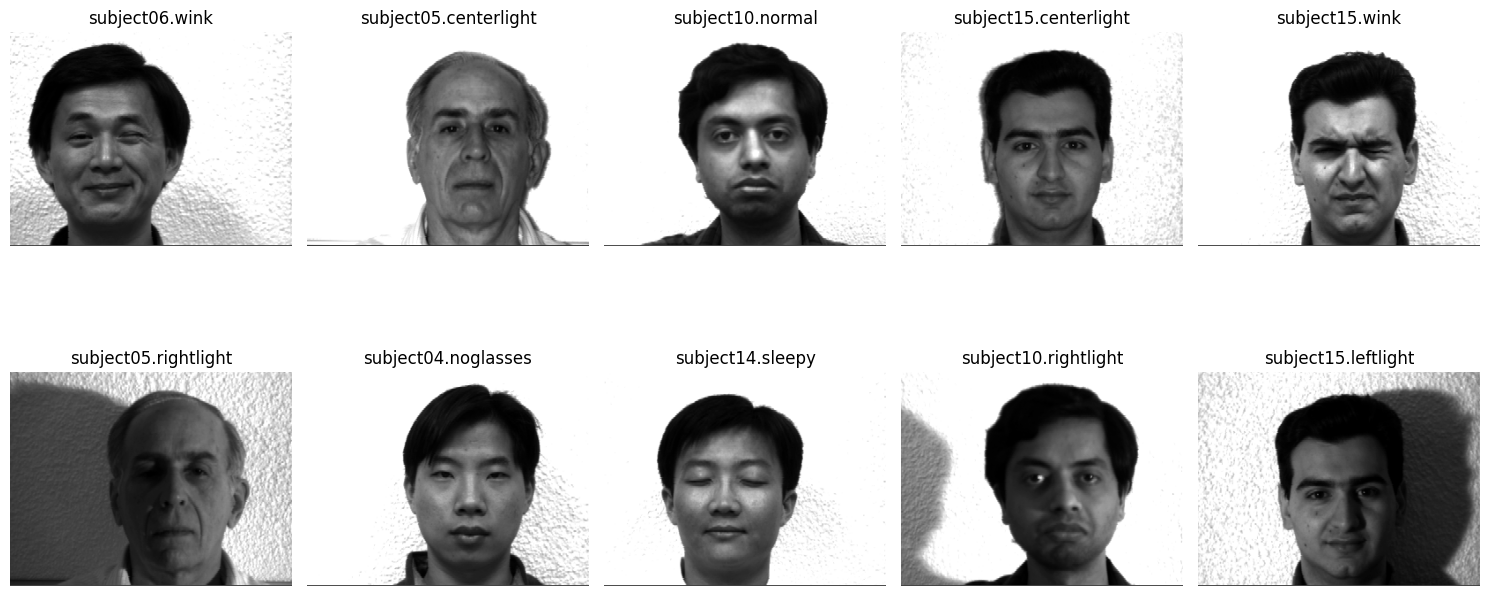

In [8]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(15, 8))

for i in range(min(10, len(valid_images))):

    img = Image.open(valid_images[i]).convert("L")

    plt.subplot(2, 5, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(os.path.basename(valid_images[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import re
import pandas as pd
import os

dataset_records = []

for path in valid_images:
    filename = os.path.basename(path)

    match = re.match(
        r"(subject\d+)\.(.+)",
        filename,
        re.IGNORECASE
    )

    if match:
        identity = match.group(1)
        variation = match.group(2).lower()

        dataset_records.append({
            "image_path": path,
            "identity": identity,
            "variation": variation
        })

df = pd.DataFrame(dataset_records)

print("Total identified images:", len(df))
print("Unique individuals:", df["identity"].nunique())
print("\nIndividuals:")
print(sorted(df["identity"].unique()))

print("\nVariations:")
print(sorted(df["variation"].unique()))

Total identified images: 165
Unique individuals: 15

Individuals:
['subject01', 'subject02', 'subject03', 'subject04', 'subject05', 'subject06', 'subject07', 'subject08', 'subject09', 'subject10', 'subject11', 'subject12', 'subject13', 'subject14', 'subject15']

Variations:
['centerlight', 'glasses', 'happy', 'leftlight', 'noglasses', 'normal', 'rightlight', 'sad', 'sleepy', 'surprised', 'wink']


In [10]:
print("Images per individual:")
print(df.groupby("identity").size())

print("\nVariation distribution:")
print(df.groupby("variation").size())

print("\nDataset overview:")
display(df.head(15))

Images per individual:
identity
subject01    11
subject02    11
subject03    11
subject04    11
subject05    11
subject06    11
subject07    11
subject08    11
subject09    11
subject10    11
subject11    11
subject12    11
subject13    11
subject14    11
subject15    11
dtype: int64

Variation distribution:
variation
centerlight    15
glasses        15
happy          15
leftlight      15
noglasses      15
normal         15
rightlight     15
sad            15
sleepy         15
surprised      15
wink           15
dtype: int64

Dataset overview:


,image_path,identity,variation
0,/content/yale_dataset/yalefaces/subject06.wink,subject06,wink
1,/content/yale_dataset/yalefaces/subject05.cent...,subject05,centerlight
2,/content/yale_dataset/yalefaces/subject10.normal,subject10,normal
3,/content/yale_dataset/yalefaces/subject15.cent...,subject15,centerlight
4,/content/yale_dataset/yalefaces/subject15.wink,subject15,wink
5,/content/yale_dataset/yalefaces/subject05.righ...,subject05,rightlight
6,/content/yale_dataset/yalefaces/subject04.nogl...,subject04,noglasses
7,/content/yale_dataset/yalefaces/subject14.sleepy,subject14,sleepy
8,/content/yale_dataset/yalefaces/subject10.righ...,subject10,rightlight
9,/content/yale_dataset/yalefaces/subject15.left...,subject15,leftlight


In [11]:
from PIL import Image

image_info = []

for path in df["image_path"]:

    with Image.open(path) as img:

        image_info.append({
            "filename": os.path.basename(path),
            "width": img.width,
            "height": img.height,
            "format": img.format,
            "mode": img.mode
        })

image_info_df = pd.DataFrame(image_info)

display(image_info_df.head(10))

print("\nImage formats:")
print(image_info_df["format"].value_counts())

print("\nImage dimensions:")
print(
    image_info_df.groupby(
        ["width", "height"]
    ).size()
)

,filename,width,height,format,mode
0,subject06.wink,320,243,GIF,L
1,subject05.centerlight,320,243,GIF,L
2,subject10.normal,320,243,GIF,L
3,subject15.centerlight,320,243,GIF,L
4,subject15.wink,320,243,GIF,L
5,subject05.rightlight,320,243,GIF,L
6,subject04.noglasses,320,243,GIF,L
7,subject14.sleepy,320,243,GIF,L
8,subject10.rightlight,320,243,GIF,L
9,subject15.leftlight,320,243,GIF,L



Image formats:
format
GIF    165
Name: count, dtype: int64

Image dimensions:
width  height
320    243       165
dtype: int64


In [12]:
METADATA_PATH = os.path.join(
    PROJECT_DIR,
    "metadata.csv"
)

df.to_csv(METADATA_PATH, index=False)

print("Metadata saved successfully!")
print(METADATA_PATH)

Metadata saved successfully!
/content/drive/MyDrive/Face_Recognition_Project/metadata.csv


In [14]:
# Select the first 10 individuals
selected_identities = sorted(df["identity"].unique())[:10]

# Filter dataset automatically
project_df = df[
    df["identity"].isin(selected_identities)
].copy()

project_df = project_df.reset_index(drop=True)

print("Selected individuals:")
print(selected_identities)

print("\nTotal selected images:", len(project_df))
print("Total selected individuals:",
      project_df["identity"].nunique())

print("\nImages per individual:")
print(project_df.groupby("identity").size())

Selected individuals:
['subject01', 'subject02', 'subject03', 'subject04', 'subject05', 'subject06', 'subject07', 'subject08', 'subject09', 'subject10']

Total selected images: 110
Total selected individuals: 10

Images per individual:
identity
subject01    11
subject02    11
subject03    11
subject04    11
subject05    11
subject06    11
subject07    11
subject08    11
subject09    11
subject10    11
dtype: int64


In [15]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

project_df["fold"] = -1

for fold, (train_idx, test_idx) in enumerate(
    skf.split(
        project_df["image_path"],
        project_df["identity"]
    )
):
    project_df.loc[test_idx, "fold"] = fold

print("Fold distribution:")
print(project_df.groupby("fold").size())

print("\nIdentity distribution per fold:")
print(
    project_df.groupby(["fold", "identity"]).size()
)

Fold distribution:
fold
0    37
1    37
2    36
dtype: int64

Identity distribution per fold:
fold  identity 
0     subject01    4
      subject02    3
      subject03    4
      subject04    4
      subject05    4
      subject06    4
      subject07    4
      subject08    3
      subject09    4
      subject10    3
1     subject01    3
      subject02    4
      subject03    4
      subject04    4
      subject05    3
      subject06    4
      subject07    3
      subject08    4
      subject09    4
      subject10    4
2     subject01    4
      subject02    4
      subject03    3
      subject04    3
      subject05    4
      subject06    3
      subject07    4
      subject08    4
      subject09    3
      subject10    4
dtype: int64


In [16]:
SPLIT_PATH = os.path.join(
    PROJECT_DIR,
    "splits.csv"
)

project_df.to_csv(SPLIT_PATH, index=False)

print("Common dataset splits saved!")
print(SPLIT_PATH)

Common dataset splits saved!
/content/drive/MyDrive/Face_Recognition_Project/splits.csv


In [17]:
print("Total images:", len(project_df))
print("Unique identities:", project_df["identity"].nunique())
print("Missing fold assignments:", project_df["fold"].isna().sum())
print("Unique folds:", project_df["fold"].nunique())

assert len(project_df) == 110
assert project_df["identity"].nunique() == 10
assert project_df["fold"].notna().all()

print("\nDataset split verified successfully!")

Total images: 110
Unique identities: 10
Missing fold assignments: 0
Unique folds: 3

Dataset split verified successfully!


In [18]:
!pip install -q deepface

In [19]:
import tensorflow as tf
from deepface import DeepFace

print("TensorFlow version:", tf.__version__)

print("Available GPUs:")
print(tf.config.list_physical_devices("GPU"))

print("\nDeepFace imported successfully!")

26-11-06 14:45:53 - Directory /root/.deepface has been created
26-11-06 14:45:53 - Directory /root/.deepface/weights has been created
TensorFlow version: 2.21.0
Available GPUs:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

DeepFace imported successfully!


In [20]:
import time

start_time = time.time()

facenet_model = DeepFace.build_model("Facenet")

model_loading_time = time.time() - start_time

print("FaceNet loaded successfully!")
print("Model loading time:", round(model_loading_time, 2), "seconds")

26-11-06 14:46:16 - 🔗 facenet_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/facenet_weights.h5 to /root/.deepface/weights/facenet_weights.h5...


Downloading...
From: https://github.com/serengil/deepface_models/releases/download/v1.0/facenet_weights.h5
To: /root/.deepface/weights/facenet_weights.h5
 35%|███▍      | 32.0M/92.2M [00:00<00:01, 39.9MB/s]

26-11-06 14:46:18 - ⚠️ Downloading facenet_weights.h5 from https://github.com/serengil/deepface_models/releases/download/v1.0/facenet_weights.h5 failed (("Connection broken: ConnectionResetError(104, 'Connection reset by peer')", ConnectionResetError(104, 'Connection reset by peer'))). Trying the backup source https://huggingface.co/serengil/deepface/resolve/main/facenet_weights.h5...
26-11-06 14:46:18 - 🔗 facenet_weights.h5 will be downloaded from https://huggingface.co/serengil/deepface/resolve/main/facenet_weights.h5 to /root/.deepface/weights/facenet_weights.h5...


Downloading...
From: https://huggingface.co/serengil/deepface/resolve/main/facenet_weights.h5
To: /root/.deepface/weights/facenet_weights.h5

  0%|          | 0.00/92.2M [00:00<?, ?B/s]
  1%|          | 524k/92.2M [00:03<09:09, 167kB/s]
  1%|          | 1.05M/92.2M [00:03<04:08, 367kB/s]
  2%|▏         | 1.57M/92.2M [00:04<03:28, 435kB/s]
 11%|█▏        | 10.5M/92.2M [00:05<00:21, 3.72MB/s]
 16%|█▋        | 15.2M/92.2M [00:05<00:14, 5.41MB/s]
 18%|█▊        | 16.3M/92.2M [00:05<00:14, 5.34MB/s]
 38%|███▊      | 35.1M/92.2M [00:05<00:02, 19.5MB/s]
 56%|█████▌    | 51.4M/92.2M [00:05<00:01, 33.6MB/s]
 73%|███████▎  | 67.1M/92.2M [00:05<00:00, 48.9MB/s]
100%|██████████| 92.2M/92.2M [00:06<00:00, 14.7MB/s]
 36%|███▌      | 33.0M/92.2M [00:08<00:14, 4.10MB/s]


FaceNet loaded successfully!
Model loading time: 12.99 seconds


In [21]:
print("Model name:", facenet_model.model_name)
print("Input shape:", facenet_model.input_shape)
print("Output shape:", facenet_model.output_shape)

Model name: FaceNet-128d
Input shape: (160, 160)
Output shape: 128


In [22]:
from PIL import Image
import numpy as np

def preprocess_image(image_path):
    img = Image.open(image_path).convert("RGB")
    img = img.resize((160, 160))
    return np.array(img)

# Test one image
sample_path = project_df.iloc[0]["image_path"]

sample_image = preprocess_image(sample_path)

print("Image shape:", sample_image.shape)
print("Image datatype:", sample_image.dtype)

Image shape: (160, 160, 3)
Image datatype: uint8


In [23]:
import time
import pandas as pd
import numpy as np
from deepface import DeepFace

embeddings = []
successful_records = []
failed_records = []

start_time = time.time()

for index, row in project_df.iterrows():

    try:
        image = preprocess_image(row["image_path"])

        result = DeepFace.represent(
            img_path=image,
            model_name="Facenet",
            detector_backend="skip",
            enforce_detection=False,
            align=False,
            normalization="Facenet"
        )

        embedding = result[0]["embedding"]

        embeddings.append(embedding)

        successful_records.append({
            "image_path": row["image_path"],
            "identity": row["identity"],
            "variation": row["variation"],
            "fold": row["fold"]
        })

    except Exception as e:
        failed_records.append({
            "image": row["image_path"],
            "error": str(e)
        })

    if (index + 1) % 10 == 0:
        print(f"Processed {index + 1}/{len(project_df)}")

extraction_time = time.time() - start_time

X = np.array(embeddings, dtype=np.float32)

embedding_df = pd.DataFrame(successful_records)

print("\nExtraction completed!")
print("Successful images:", len(X))
print("Failed images:", len(failed_records))
print("Embedding shape:", X.shape)
print("Extraction time:", round(extraction_time, 2), "seconds")

Processed 10/110
Processed 20/110
Processed 30/110
Processed 40/110
Processed 50/110
Processed 60/110
Processed 70/110
Processed 80/110
Processed 90/110
Processed 100/110
Processed 110/110

Extraction completed!
Successful images: 110
Failed images: 0
Embedding shape: (110, 128)
Extraction time: 56.51 seconds


In [24]:
from sklearn.preprocessing import normalize

X = normalize(X, norm="l2")

print("Normalized embedding shape:", X.shape)
print("First embedding norm:", np.linalg.norm(X[0]))

Normalized embedding shape: (110, 128)
First embedding norm: 1.0


In [25]:
RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "facenet"
)

os.makedirs(RESULT_DIR, exist_ok=True)

np.savez_compressed(
    os.path.join(RESULT_DIR, "facenet_embeddings.npz"),
    X=X,
    identities=embedding_df["identity"].values,
    variations=embedding_df["variation"].values,
    folds=embedding_df["fold"].values,
    image_paths=embedding_df["image_path"].values
)

print("FaceNet embeddings saved successfully!")

FaceNet embeddings saved successfully!


In [26]:
print("Embedding shape:", X.shape)
print("Metadata shape:", embedding_df.shape)

print("\nImages per identity:")
print(embedding_df["identity"].value_counts())

print("\nImages per fold:")
print(embedding_df["fold"].value_counts().sort_index())

print("\nMissing values:")
print(embedding_df.isnull().sum())

assert X.shape[0] == len(embedding_df)
assert X.shape[1] == 128
assert embedding_df["identity"].nunique() == 10
assert embedding_df["fold"].nunique() == 3

print("\nAll validation checks passed!")

Embedding shape: (110, 128)
Metadata shape: (110, 4)

Images per identity:
identity
subject06    11
subject05    11
subject10    11
subject04    11
subject07    11
subject08    11
subject03    11
subject01    11
subject02    11
subject09    11
Name: count, dtype: int64

Images per fold:
fold
0    37
1    37
2    36
Name: count, dtype: int64

Missing values:
image_path    0
identity      0
variation     0
fold          0
dtype: int64

All validation checks passed!


In [27]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time
import pandas as pd
import numpy as np

In [28]:
fold_results = []
all_predictions = []

total_training_time = 0
total_prediction_time = 0

for fold in sorted(embedding_df["fold"].unique()):

    train_mask = embedding_df["fold"].values != fold
    test_mask = embedding_df["fold"].values == fold

    X_train = X[train_mask]
    X_test = X[test_mask]

    y_train = embedding_df.loc[train_mask, "identity"].values
    y_test = embedding_df.loc[test_mask, "identity"].values

    # Initialize SVM
    svm_model = SVC(
        kernel="linear",
        C=1.0
    )

    # Training
    start = time.perf_counter()
    svm_model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    # Prediction
    start = time.perf_counter()
    predictions = svm_model.predict(X_test)
    prediction_time = time.perf_counter() - start

    total_training_time += training_time
    total_prediction_time += prediction_time

    # Evaluation
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, predictions,
        average="macro",
        zero_division=0
    )

    fold_results.append({
        "fold": fold,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "training_time": training_time,
        "prediction_time": prediction_time
    })

    # Save individual predictions
    test_rows = embedding_df.loc[test_mask]

    for i, (_, row) in enumerate(test_rows.iterrows()):
        all_predictions.append({
            "image_path": row["image_path"],
            "fold": fold,
            "actual": y_test[i],
            "predicted": predictions[i],
            "variation": row["variation"]
        })

    print(f"Fold {fold}: Accuracy = {accuracy:.4f}")

results_df = pd.DataFrame(fold_results)
predictions_df = pd.DataFrame(all_predictions)

print("\nTraining and evaluation completed!")

Fold 0: Accuracy = 1.0000
Fold 1: Accuracy = 0.9730
Fold 2: Accuracy = 1.0000

Training and evaluation completed!


In [29]:
print("FaceNet + SVM Performance")

display(results_df)

print("\nAverage Performance:")

display(
    results_df[
        ["accuracy", "precision", "recall", "f1_score"]
    ].mean().to_frame("Average").T
)

FaceNet + SVM Performance


,fold,accuracy,precision,recall,f1_score,training_time,prediction_time
0,0,1.000000,1.00,1.000,1.000000,0.005381,0.000560
1,1,0.972973,0.98,0.975,0.974603,0.001832,0.000413
2,2,1.000000,1.00,1.000,1.000000,0.001744,0.000429



Average Performance:


,accuracy,precision,recall,f1_score
Average,0.990991,0.993333,0.991667,0.991534


In [30]:
print("FaceNet + SVM Performance")

display(results_df)

print("\nAverage Performance:")

display(
    results_df[
        ["accuracy", "precision", "recall", "f1_score"]
    ].mean().to_frame("Average").T
)

FaceNet + SVM Performance


,fold,accuracy,precision,recall,f1_score,training_time,prediction_time
0,0,1.000000,1.00,1.000,1.000000,0.005381,0.000560
1,1,0.972973,0.98,0.975,0.974603,0.001832,0.000413
2,2,1.000000,1.00,1.000,1.000000,0.001744,0.000429



Average Performance:


,accuracy,precision,recall,f1_score
Average,0.990991,0.993333,0.991667,0.991534


In [31]:
results_df.to_csv(
    os.path.join(RESULT_DIR, "metrics.csv"),
    index=False
)

predictions_df.to_csv(
    os.path.join(RESULT_DIR, "predictions.csv"),
    index=False
)

print("Results saved successfully!")

Results saved successfully!


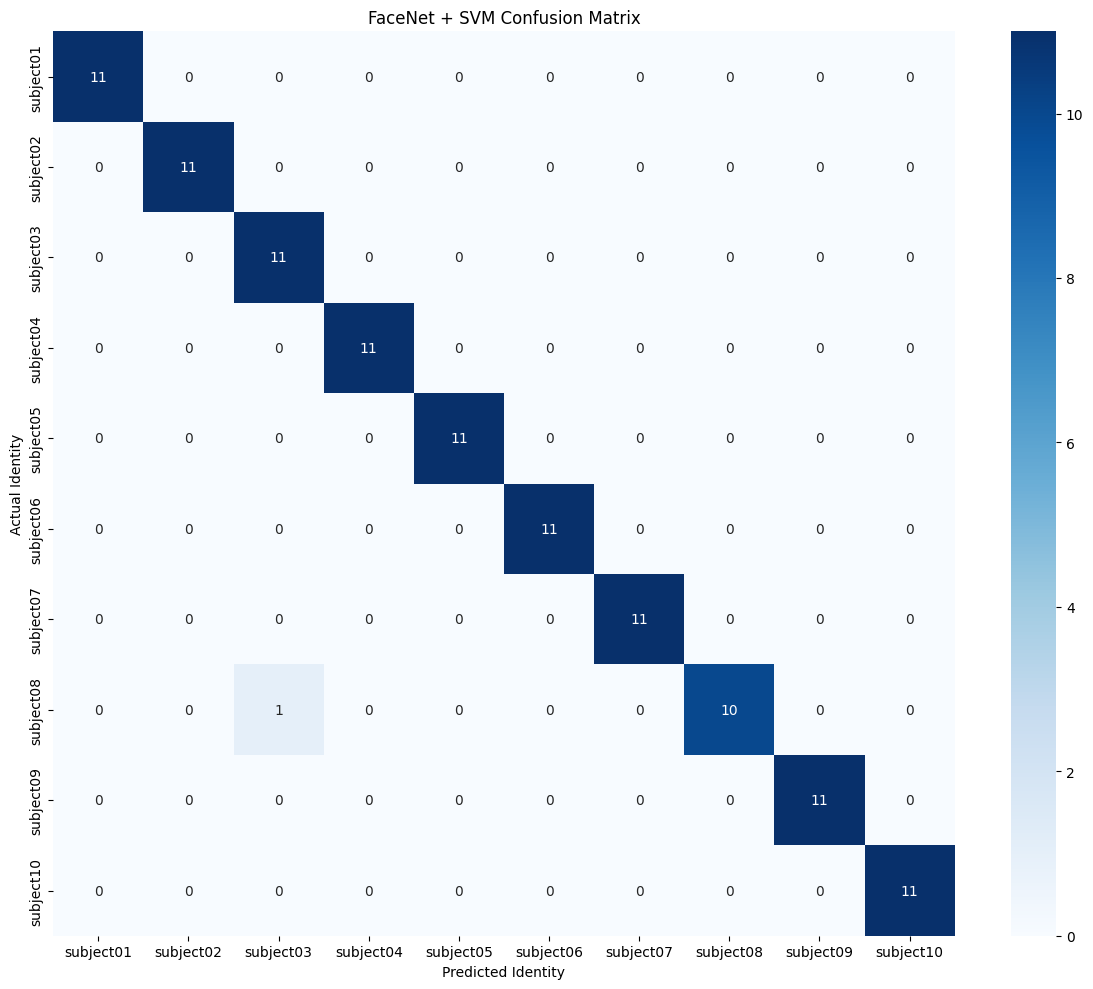

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix

labels = sorted(predictions_df["actual"].unique())

cm = confusion_matrix(
    predictions_df["actual"],
    predictions_df["predicted"],
    labels=labels
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Identity")
plt.ylabel("Actual Identity")
plt.title("FaceNet + SVM Confusion Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "confusion_matrix.png"),
    dpi=300
)

plt.show()

In [38]:
from sklearn.metrics import classification_report

report = classification_report(
    predictions_df["actual"],
    predictions_df["predicted"],
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df)

report_df.to_csv(
    os.path.join(RESULT_DIR, "classification_report.csv")
)

,precision,recall,f1-score,support
subject01,1.000000,1.000000,1.000000,11.000000
subject02,1.000000,1.000000,1.000000,11.000000
subject03,0.916667,1.000000,0.956522,11.000000
subject04,1.000000,1.000000,1.000000,11.000000
subject05,1.000000,1.000000,1.000000,11.000000
subject06,1.000000,1.000000,1.000000,11.000000
subject07,1.000000,1.000000,1.000000,11.000000
subject08,1.000000,0.909091,0.952381,11.000000
subject09,1.000000,1.000000,1.000000,11.000000
subject10,1.000000,1.000000,1.000000,11.000000


In [39]:
variation_results = (
    predictions_df
    .groupby("variation")
    .apply(
        lambda group: pd.Series({
            "total_images": len(group),
            "correct_predictions": (
                group["actual"] == group["predicted"]
            ).sum(),
            "accuracy": (
                group["actual"] == group["predicted"]
            ).mean()
        }),
        include_groups=False
    )
    .reset_index()
)

display(variation_results)

variation_results.to_csv(
    os.path.join(RESULT_DIR, "variation_accuracy.csv"),
    index=False
)

,variation,total_images,correct_predictions,accuracy
0,centerlight,10.0,10.0,1.0
1,glasses,10.0,10.0,1.0
2,happy,10.0,10.0,1.0
3,leftlight,10.0,10.0,1.0
4,noglasses,10.0,9.0,0.9
5,normal,10.0,10.0,1.0
6,rightlight,10.0,10.0,1.0
7,sad,10.0,10.0,1.0
8,sleepy,10.0,10.0,1.0
9,surprised,10.0,10.0,1.0


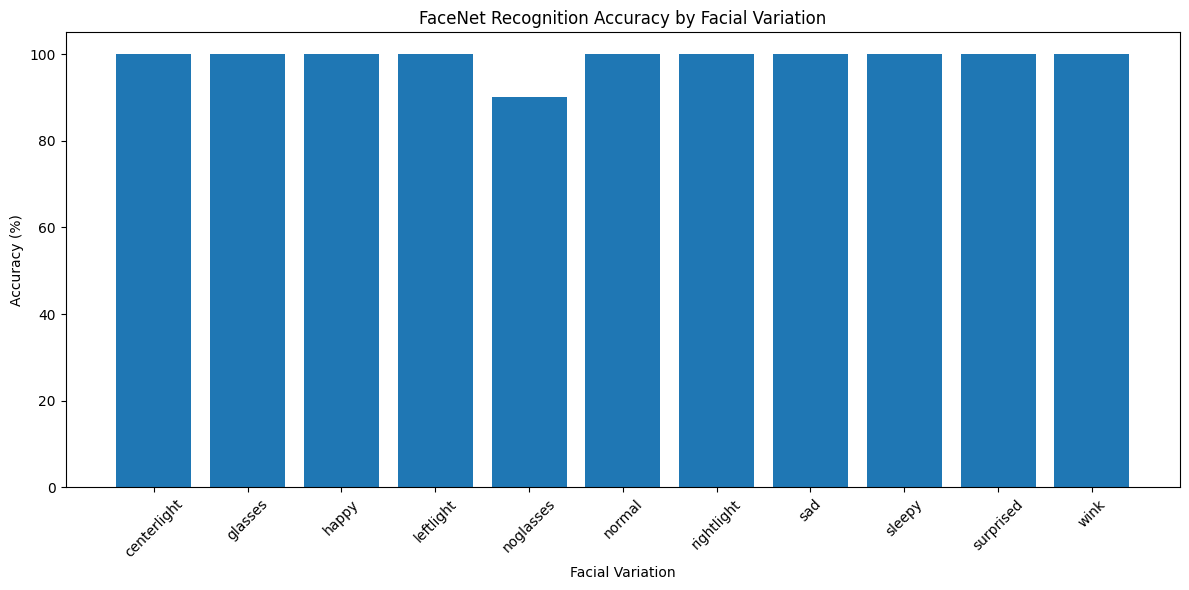

In [40]:
plt.figure(figsize=(12, 6))

plt.bar(
    variation_results["variation"],
    variation_results["accuracy"] * 100
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Facial Variation")
plt.title("FaceNet Recognition Accuracy by Facial Variation")

plt.xticks(rotation=45)
plt.ylim(0, 105)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "variation_accuracy.png"),
    dpi=300
)

plt.show()

In [41]:
import os

print("FaceNet Results Folder:")

for file in sorted(os.listdir(RESULT_DIR)):
    path = os.path.join(RESULT_DIR, file)

    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f"{file} — {size_kb:.2f} KB")

FaceNet Results Folder:
classification_report.csv — 0.58 KB
confusion_matrix.png — 201.84 KB
facenet_embeddings.npz — 50.26 KB
metrics.csv — 0.29 KB
predictions.csv — 8.67 KB
variation_accuracy.csv — 0.29 KB
variation_accuracy.png — 163.97 KB
